# Financial Econometrics — Homework 3
## Estimating and Testing the Fama–French 3-Factor Model

This notebook walks step by step through the data preparation, exploratory checks, descriptive statistics, and manual OLS estimation of the Fama–French 3-factor model for **IBM**, **General Electric (`GE`)**, and **Johnson & Johnson (`JNJ`)** from **January 1980 to December 2019**.

All generated tables and vector PDF figures are displayed inline and saved to `output/`.

In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

TICKERS = ["IBM", "GE", "JNJ"]
START_DATE = "1980-01-01"
END_DATE = "2020-01-01"  # exclusive upper bound -> ends Dec 31, 2019
START_YYYYMM = 198002  # first monthly return (Jan 1980 lost to differencing)
END_YYYYMM = 201912

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FF_ZIP_PATH = DATA_DIR / "F-F_Research_Data_Factors_CSV.zip"
FF_CSV_PATH = DATA_DIR / "F-F_Research_Data_Factors.csv"
YAHOO_CSV_PATH = DATA_DIR / "yahoo_adj_close_1980_2019.csv"

plt.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## Step 1: Extract and Inspect the Fama–French 3-Factor Data

The Kenneth R. French CSV is stored compressed in `data/F-F_Research_Data_Factors_CSV.zip`. First we unzip it if needed and inspect its raw structure: it starts with 3 descriptive header lines and contains two separate data blocks (monthly factors first, followed by annual factors starting around line 1210).

In [2]:
if FF_ZIP_PATH.exists() and (
    not FF_CSV_PATH.exists()
    or FF_ZIP_PATH.stat().st_mtime > FF_CSV_PATH.stat().st_mtime
):
    with zipfile.ZipFile(FF_ZIP_PATH, "r") as zf:
        members = [m for m in zf.namelist() if Path(m).name == FF_CSV_PATH.name]
        if not members:
            raise FileNotFoundError(f"{FF_CSV_PATH.name} not found in {FF_ZIP_PATH}")
        with zf.open(members[0]) as src, open(FF_CSV_PATH, "wb") as dst:
            dst.write(src.read())

with open(FF_CSV_PATH, "r", encoding="utf-8") as f:
    raw_lines = f.readlines()

print(f"Total lines in CSV: {len(raw_lines)}")
print("\n--- Lines 1 to 10 ---")
print("".join(raw_lines[:10]))
print("--- Lines 1206 to 1215 ---")
print("".join(raw_lines[1205:1215]))

Total lines in CSV: 1312

--- Lines 1 to 10 ---
This file was created using the 202609 CRSP database.
The 1-month TBill rate data until 202405 are from Ibbotson Associates. Starting from 202406, the 1-month TBill rate is from ICE BofA US 1-Month Treasury Bill Index. 
The annual TBill return is compounded from the monthly T-bill rates from January to December. 

,Mkt-RF,SMB,HML,RF
192607,   2.89,  -2.42,  -2.75,   0.22
192608,   2.64,  -1.44,   4.13,   0.25
192609,   0.38,  -1.36,   0.05,   0.23
192610,  -3.27,  -0.18,   0.78,   0.32
192611,   2.54,  -0.17,  -0.48,   0.31

--- Lines 1206 to 1215 ---
202607,  -0.61,  -1.92,   2.11,   0.33
202608,   2.56,   0.34,  -3.54,   0.29
202609,  -1.07,  -3.16,  -1.55,   0.31

 Annual Factors: January-December 
,Mkt-RF,SMB,HML,RF
  1927,  29.44,  -3.05,  -3.36,   3.12
  1928,  35.56,   3.73,  -5.26,   3.56
  1929, -19.58, -30.68,  11.86,   4.75
  1930, -31.14,  -5.53, -11.76,   2.41



We parse only the monthly block (stopping at the blank line before `Annual Factors: January-December`) and divide `Mkt-RF`, `SMB`, `HML`, and `RF` by `100` to convert from percentage points to decimal returns.

In [3]:
rows = []
for line in raw_lines:
    stripped = line.strip()
    if not stripped:
        if rows:  # blank line after monthly block
            break
        continue
    if stripped.startswith("Annual Factors"):
        break
    parts = [p.strip() for p in stripped.split(",")]
    if len(parts) == 5 and (
        parts[0] == "" or (parts[0].isdigit() and len(parts[0]) == 6)
    ):
        rows.append(parts)

ff_all = pd.DataFrame(rows[1:], columns=["YYYYMM", "Mkt-RF", "SMB", "HML", "RF"])
ff_all["YYYYMM"] = ff_all["YYYYMM"].astype(int)
for col in ["Mkt-RF", "SMB", "HML", "RF"]:
    ff_all[col] = ff_all[col].astype(float) / 100.0  # percent -> decimal

assert not ff_all.isna().any().any(), "Unexpected NaNs in Fama-French monthly data."
print(
    f"Parsed monthly Fama-French rows: {len(ff_all)} ({ff_all['YYYYMM'].min()} to {ff_all['YYYYMM'].max()})"
)
display(ff_all.head())
display(ff_all.tail())

Parsed monthly Fama-French rows: 1203 (192607 to 202609)


,YYYYMM,Mkt-RF,SMB,HML,RF
0,192607,0.0289,-0.0242,-0.0275,0.0022
1,192608,0.0264,-0.0144,0.0413,0.0025
2,192609,0.0038,-0.0136,0.0005,0.0023
3,192610,-0.0327,-0.0018,0.0078,0.0032
4,192611,0.0254,-0.0017,-0.0048,0.0031


,YYYYMM,Mkt-RF,SMB,HML,RF
1198,202605,0.0491,-0.0159,-0.0231,0.0031
1199,202606,-0.0107,0.0339,0.0358,0.0029
1200,202607,-0.0061,-0.0192,0.0211,0.0033
1201,202608,0.0256,0.0034,-0.0354,0.0029
1202,202609,-0.0107,-0.0316,-0.0155,0.0031


## Step 2: Load Monthly Adjusted Close Prices (IBM, GE, JNJ)

We need monthly Adjusted Close prices from January 1980 to December 2019 (480 monthly observations). Because Yahoo Finance's `1mo` endpoint omits `JNJ` before January 1985, we download daily Adjusted Close prices and resample to month-end (`ME`) closing prices, caching the result in `data/yahoo_adj_close_1980_2019.csv`.

In [4]:
if YAHOO_CSV_PATH.exists():
    adj_close = pd.read_csv(YAHOO_CSV_PATH, index_col=0, parse_dates=True)[TICKERS]
else:
    import yfinance as yf

    raw_prices = yf.download(
        TICKERS,
        start=START_DATE,
        end=END_DATE,
        interval="1d",
        auto_adjust=False,
        progress=False,
    )
    adj_close = raw_prices["Adj Close"][TICKERS].resample("ME").last()
    adj_close.to_csv(YAHOO_CSV_PATH)

assert adj_close.shape == (480, 3), f"Expected (480, 3), got {adj_close.shape}"
assert not adj_close.isna().any().any(), "Missing values in Adjusted Close prices."

print("Adjusted Close shape:", adj_close.shape)
display(adj_close.head())
display(adj_close.tail())

Adjusted Close shape: (480, 3)


,IBM,GE,JNJ
Date,,,
1980-01-31,4.324205,1.585521,0.512046
1980-02-29,4.051309,1.469262,0.469379
1980-03-31,3.556861,1.407129,0.485623
1980-04-30,3.501033,1.388855,0.518967
1980-05-31,3.588926,1.469657,0.551180


,IBM,GE,JNJ
Date,,,
2019-08-31,96.285820,39.745033,105.965935
2019-09-30,103.312088,43.115726,106.807999
2019-10-31,95.007019,48.131424,109.003929
2019-11-30,96.646713,54.352818,114.289474
2019-12-31,96.351990,53.871105,121.255402


## Step 3: Compute Monthly Returns, Align Dates, and Form Excess Returns

Computing simple monthly returns $R_{i,t} = P_{i,t}/P_{i,t-1} - 1$ drops the first price observation (January 1980), leaving $T = 479$ observations from February 1980 to December 2019. We slice the Fama–French series to the exact matching `YYYYMM` range (`198002`–`201912`), verify date alignment and unit scales, and compute excess returns $y_{i,t} = R_{i,t} - RF_t$.

In [5]:
stock_returns = adj_close.pct_change().dropna()
stock_yyyymm = (stock_returns.index.year * 100 + stock_returns.index.month).to_numpy()

ff_sample = ff_all[
    (ff_all["YYYYMM"] >= START_YYYYMM) & (ff_all["YYYYMM"] <= END_YYYYMM)
].reset_index(drop=True)

assert len(stock_returns) == 479 and len(ff_sample) == 479
assert np.array_equal(stock_yyyymm, ff_sample["YYYYMM"].to_numpy()), "Date mismatch!"

excess_returns = pd.DataFrame(index=stock_returns.index)
for ticker in TICKERS:
    excess_returns[ticker] = (
        stock_returns[ticker].to_numpy() - ff_sample["RF"].to_numpy()
    )

# Save unified aligned dataset
cleaned = pd.DataFrame({"YYYYMM": ff_sample["YYYYMM"].to_numpy()})
for ticker in TICKERS:
    cleaned[f"R_{ticker}"] = stock_returns[ticker].to_numpy()
    cleaned[f"y_{ticker}"] = excess_returns[ticker].to_numpy()
for col in ["Mkt-RF", "SMB", "HML", "RF"]:
    cleaned[col] = ff_sample[col].to_numpy()
cleaned.to_csv(DATA_DIR / "cleaned_dataset_1980_2019.csv", index=False)

print(
    f"Aligned sample: {ff_sample['YYYYMM'].iloc[0]} to {ff_sample['YYYYMM'].iloc[-1]} (T = {len(excess_returns)})"
)
display(excess_returns.head())

Aligned sample: 198002 to 201912 (T = 479)


,IBM,GE,JNJ
Date,,,
1980-02-29,-0.072009,-0.082225,-0.092227
1980-03-31,-0.134146,-0.054389,0.022508
1980-04-30,-0.028296,-0.025587,0.056061
1980-05-31,0.017005,0.050079,0.053972
1980-06-30,0.054847,0.034304,-0.024850


## Step 4: Descriptive Statistics and Return Histograms

We compute monthly summary statistics (mean, standard deviation, min, median, max, skewness, excess kurtosis, and annualized mean/volatility) for raw returns, excess returns, and the Fama–French factors, and inspect their distributions.

In [6]:
series_map = {
    "IBM (Raw Return)": stock_returns["IBM"].to_numpy(),
    "GE (Raw Return)": stock_returns["GE"].to_numpy(),
    "JNJ (Raw Return)": stock_returns["JNJ"].to_numpy(),
    "IBM (Excess Return)": excess_returns["IBM"].to_numpy(),
    "GE (Excess Return)": excess_returns["GE"].to_numpy(),
    "JNJ (Excess Return)": excess_returns["JNJ"].to_numpy(),
    "Mkt-RF": ff_sample["Mkt-RF"].to_numpy(),
    "SMB": ff_sample["SMB"].to_numpy(),
    "HML": ff_sample["HML"].to_numpy(),
    "RF": ff_sample["RF"].to_numpy(),
}

records = []
for name, arr in series_map.items():
    mean_m = float(np.mean(arr))
    std_m = float(np.std(arr, ddof=1))
    records.append(
        {
            "Series": name,
            "N": len(arr),
            "Mean": mean_m,
            "Std": std_m,
            "Min": float(np.min(arr)),
            "Median": float(np.median(arr)),
            "Max": float(np.max(arr)),
            "Skewness": float(stats.skew(arr, bias=False)),
            "Excess_Kurtosis": float(stats.kurtosis(arr, fisher=True, bias=False)),
            "Ann_Mean": 12.0 * mean_m,
            "Ann_Std": np.sqrt(12.0) * std_m,
        }
    )

desc_df = pd.DataFrame(records)
desc_df.to_csv(OUTPUT_DIR / "descriptive_stats.csv", index=False)
display(desc_df.round(4))

,Series,N,Mean,Std,Min,Median,Max,Skewness,Excess_Kurtosis,Ann_Mean,Ann_Std
0,IBM (Raw Return),479,0.0092,0.0733,-0.2619,0.0078,0.3538,0.1901,2.1160,0.1100,0.2539
1,GE (Raw Return),479,0.0101,0.0730,-0.2778,0.0050,0.3421,-0.0903,2.0436,0.1207,0.2528
2,JNJ (Raw Return),479,0.0131,0.0574,-0.1734,0.0132,0.1881,-0.0156,0.5910,0.1573,0.1989
3,IBM (Excess Return),479,0.0057,0.0733,-0.2647,0.0056,0.3524,0.1887,2.0898,0.0686,0.2540
4,GE (Excess Return),479,0.0066,0.0728,-0.2779,0.0023,0.3400,-0.0642,2.0373,0.0793,0.2523
5,JNJ (Excess Return),479,0.0097,0.0573,-0.1812,0.0113,0.1843,-0.0625,0.6155,0.1160,0.1984
6,Mkt-RF,479,0.0067,0.0439,-0.2319,0.0112,0.1245,-0.7603,2.3997,0.0808,0.1522
7,SMB,479,0.0006,0.0295,-0.1739,0.0008,0.2134,0.5571,7.9592,0.0077,0.1024
8,HML,479,0.0024,0.0290,-0.1101,0.0009,0.1225,0.2569,1.7917,0.0285,0.1004
9,RF,479,0.0034,0.0029,0.0000,0.0034,0.0135,0.8607,0.6364,0.0414,0.0101


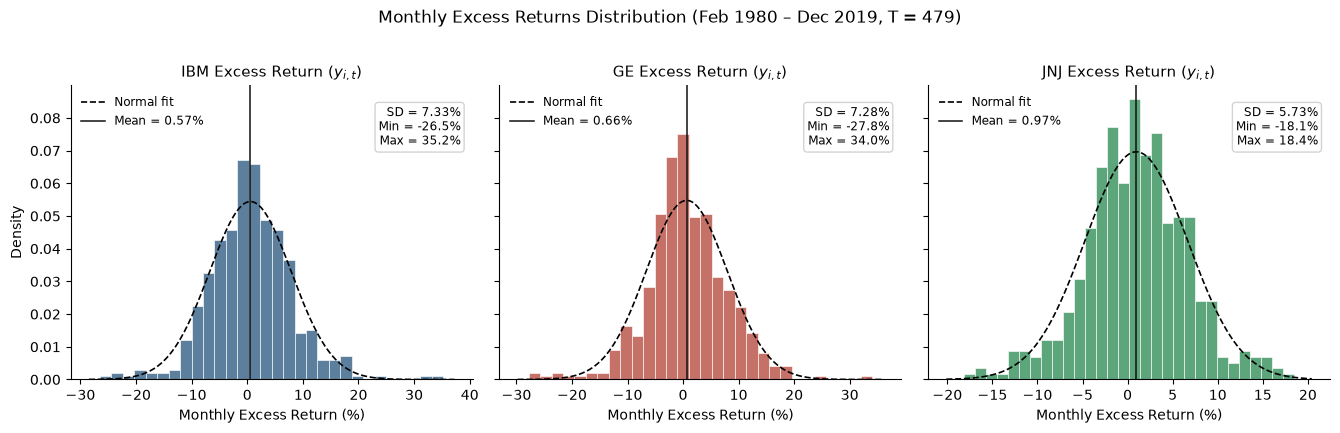

In [7]:
# Histogram 1: Monthly Excess Stock Returns (saved to output/hist_stock_excess_returns.pdf)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)
colors = ["#1f4e79", "#b03a2e", "#1e8449"]

for ax, ticker, color in zip(axes, TICKERS, colors):
    vals = excess_returns[ticker].to_numpy() * 100.0
    mean_v = np.mean(vals)
    std_v = np.std(vals, ddof=1)
    ax.hist(
        vals,
        bins=30,
        density=True,
        color=color,
        alpha=0.72,
        edgecolor="white",
        linewidth=0.6,
    )
    x_grid = np.linspace(vals.min() - 2, vals.max() + 2, 300)
    ax.plot(
        x_grid,
        stats.norm.pdf(x_grid, mean_v, std_v),
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Normal fit",
    )
    ax.axvline(
        mean_v,
        color="#111111",
        linestyle="-",
        linewidth=1.1,
        label=f"Mean = {mean_v:.2f}%",
    )
    ax.set_title(f"{ticker} Excess Return ($y_{{i,t}}$)")
    ax.set_xlabel("Monthly Excess Return (%)")
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")
    ax.text(
        0.97,
        0.93,
        f"SD = {std_v:.2f}%\nMin = {vals.min():.1f}%\nMax = {vals.max():.1f}%",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8.5,
        bbox=dict(
            boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="#cccccc"
        ),
    )

axes[0].set_ylabel("Density")
fig.suptitle(
    "Monthly Excess Returns Distribution (Feb 1980 – Dec 2019, T = 479)",
    fontsize=12,
    y=1.02,
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hist_stock_excess_returns.pdf", bbox_inches="tight")
plt.show()

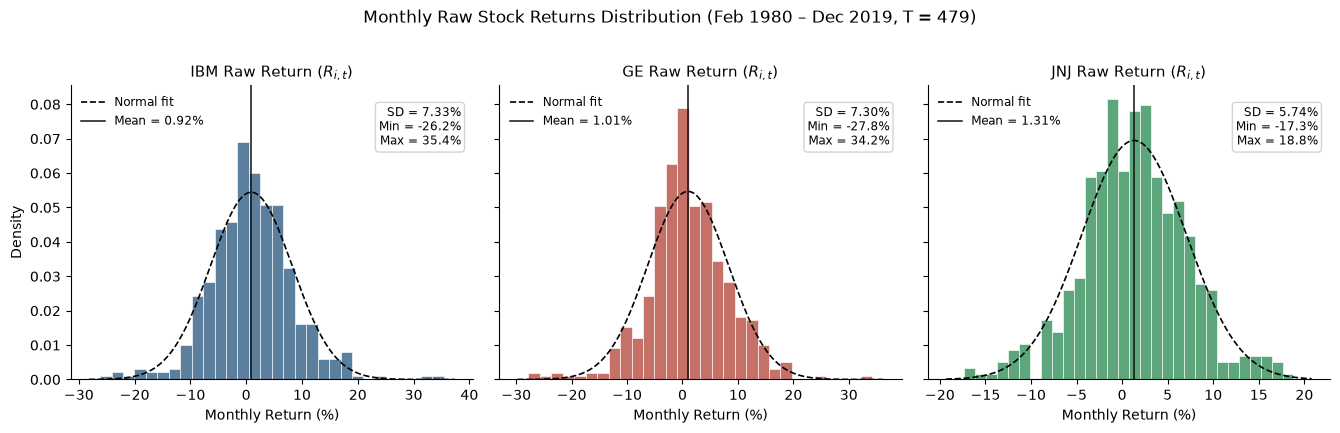

In [8]:
# Histogram 2: Monthly Raw Stock Returns (saved to output/hist_stock_raw_returns.pdf)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)

for ax, ticker, color in zip(axes, TICKERS, colors):
    vals = stock_returns[ticker].to_numpy() * 100.0
    mean_v = np.mean(vals)
    std_v = np.std(vals, ddof=1)
    ax.hist(
        vals,
        bins=30,
        density=True,
        color=color,
        alpha=0.72,
        edgecolor="white",
        linewidth=0.6,
    )
    x_grid = np.linspace(vals.min() - 2, vals.max() + 2, 300)
    ax.plot(
        x_grid,
        stats.norm.pdf(x_grid, mean_v, std_v),
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Normal fit",
    )
    ax.axvline(
        mean_v,
        color="#111111",
        linestyle="-",
        linewidth=1.1,
        label=f"Mean = {mean_v:.2f}%",
    )
    ax.set_title(f"{ticker} Raw Return ($R_{{i,t}}$)")
    ax.set_xlabel("Monthly Return (%)")
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")
    ax.text(
        0.97,
        0.93,
        f"SD = {std_v:.2f}%\nMin = {vals.min():.1f}%\nMax = {vals.max():.1f}%",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8.5,
        bbox=dict(
            boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="#cccccc"
        ),
    )

axes[0].set_ylabel("Density")
fig.suptitle(
    "Monthly Raw Stock Returns Distribution (Feb 1980 – Dec 2019, T = 479)",
    fontsize=12,
    y=1.02,
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hist_stock_raw_returns.pdf", bbox_inches="tight")
plt.show()

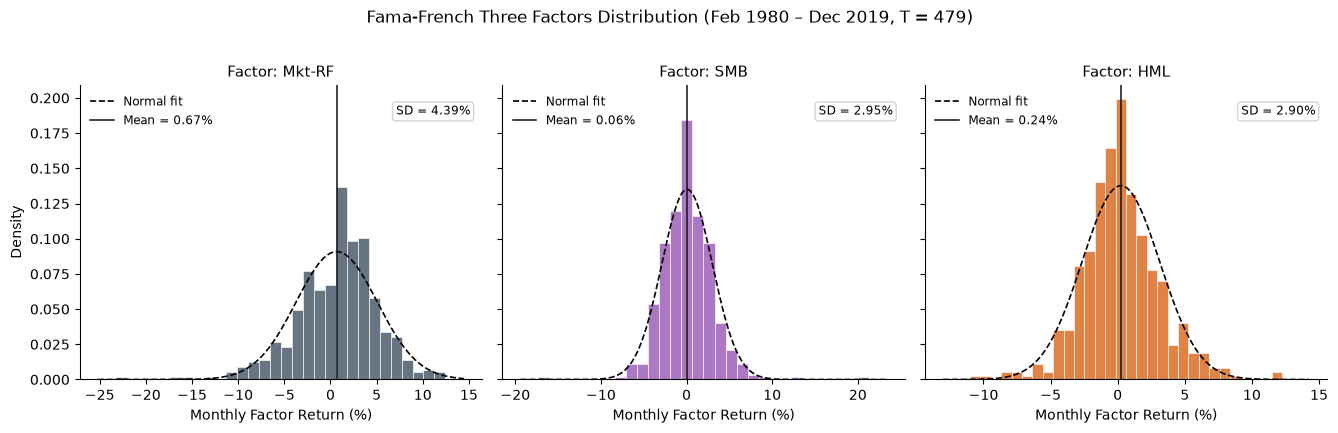

In [9]:
# Histogram 3: Fama-French Three Factors (saved to output/hist_ff_factors.pdf)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)
factor_names = ["Mkt-RF", "SMB", "HML"]
f_colors = ["#2c3e50", "#8e44ad", "#d35400"]

for ax, fname, color in zip(axes, factor_names, f_colors):
    vals = ff_sample[fname].to_numpy() * 100.0
    mean_v = np.mean(vals)
    std_v = np.std(vals, ddof=1)
    ax.hist(
        vals,
        bins=30,
        density=True,
        color=color,
        alpha=0.72,
        edgecolor="white",
        linewidth=0.6,
    )
    x_grid = np.linspace(vals.min() - 2, vals.max() + 2, 300)
    ax.plot(
        x_grid,
        stats.norm.pdf(x_grid, mean_v, std_v),
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Normal fit",
    )
    ax.axvline(
        mean_v,
        color="#111111",
        linestyle="-",
        linewidth=1.1,
        label=f"Mean = {mean_v:.2f}%",
    )
    ax.set_title(f"Factor: {fname}")
    ax.set_xlabel("Monthly Factor Return (%)")
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")
    ax.text(
        0.97,
        0.93,
        f"SD = {std_v:.2f}%",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8.5,
        bbox=dict(
            boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="#cccccc"
        ),
    )

axes[0].set_ylabel("Density")
fig.suptitle(
    "Fama-French Three Factors Distribution (Feb 1980 – Dec 2019, T = 479)",
    fontsize=12,
    y=1.02,
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hist_ff_factors.pdf", bbox_inches="tight")
plt.show()

## Step 5 (Section 3.1): Manual OLS Estimation

For each firm $i \in \{\text{IBM}, \text{GE}, \text{JNJ}\}$, we write the compact model:
$$y_i = S\alpha_i + X\beta_i + \varepsilon_i = \tilde{X}\theta_i + \varepsilon_i, \qquad \tilde{X} = [S, X] \in \mathbb{R}^{479 \times 4}, \quad \theta_i = [\alpha_i, \beta_{1,i}, \beta_{2,i}, \beta_{3,i}]'.$$

We construct `S`, `X`, and `X_tilde` explicitly and estimate $\hat{\theta}_i = (\tilde{X}'\tilde{X})^{-1}\tilde{X}'y_i$ directly with matrix algebra (without using any built-in OLS function).

In [10]:
T = len(excess_returns)
K = 3
dof = T - K - 1  # 475

S = np.ones((T, 1), dtype=float)
X = ff_sample[["Mkt-RF", "SMB", "HML"]].to_numpy(dtype=float)
X_tilde = np.hstack([S, X])

print(f"T = {T}, K = {K}, df = {dof}")
print(f"Shapes -> S: {S.shape}, X: {X.shape}, X_tilde: {X_tilde.shape}")

XtX_inv = np.linalg.inv(X_tilde.T @ X_tilde)

T = 479, K = 3, df = 475
Shapes -> S: (479, 1), X: (479, 3), X_tilde: (479, 4)


In [11]:
param_names = ["alpha", "beta_MKT", "beta_SMB", "beta_HML"]
ols_rows = []
firm_details = {}
residuals_mat = np.zeros((T, len(TICKERS)), dtype=float)

for idx, ticker in enumerate(TICKERS):
    y_i = excess_returns[ticker].to_numpy(dtype=float).reshape(T, 1)

    # Manual OLS: theta_hat = (X_tilde' X_tilde)^{-1} X_tilde' y_i
    theta_hat = XtX_inv @ (X_tilde.T @ y_i)
    eps_hat = y_i - X_tilde @ theta_hat
    residuals_mat[:, idx] = eps_hat[:, 0]

    # Residual variance estimate: sigma_hat^2 = (eps_hat' eps_hat) / (T - K - 1)
    rss = float((eps_hat.T @ eps_hat)[0, 0])
    sigma2_hat = rss / dof
    sigma_hat = float(np.sqrt(sigma2_hat))

    # Parameter covariance, standard errors, t-stats, and two-sided p-values
    cov_theta_hat = sigma2_hat * XtX_inv
    se_theta_hat = np.sqrt(np.diag(cov_theta_hat))
    t_stats = theta_hat[:, 0] / se_theta_hat
    p_vals = 2.0 * stats.t.sf(np.abs(t_stats), df=dof)

    # Goodness of fit
    y_centered = y_i - np.mean(y_i)
    tss = float((y_centered.T @ y_centered)[0, 0])
    r2 = 1.0 - rss / tss
    adj_r2 = 1.0 - (1.0 - r2) * (T - 1) / dof

    firm_details[ticker] = {
        "sigma2_hat": sigma2_hat,
        "sigma_hat": sigma_hat,
        "R2": r2,
        "Adj_R2": adj_r2,
    }

    t_crit = stats.t.ppf(0.975, df=dof)
    for pname, est, se, tval, pval in zip(
        param_names, theta_hat[:, 0], se_theta_hat, t_stats, p_vals
    ):
        ols_rows.append(
            {
                "Firm": ticker,
                "Parameter": pname,
                "Estimate": est,
                "Std_Error": se,
                "t_stat": tval,
                "p_value": pval,
                "CI_95_Low": est - t_crit * se,
                "CI_95_High": est + t_crit * se,
                "sigma2_hat": sigma2_hat,
                "sigma_hat": sigma_hat,
                "R2": r2,
                "Adj_R2": adj_r2,
            }
        )

ols_df = pd.DataFrame(ols_rows)
ols_df.to_csv(OUTPUT_DIR / "ols_results.csv", index=False)
display(ols_df.round(6))

,Firm,Parameter,Estimate,Std_Error,t_stat,p_value,CI_95_Low,CI_95_High,sigma2_hat,sigma_hat,R2,Adj_R2
0,IBM,alpha,0.000345,0.002852,0.121096,0.903666,-0.005260,0.005950,0.003747,0.061215,0.307133,0.302757
1,IBM,beta_MKT,0.898111,0.067071,13.390504,0.000000,0.766319,1.029904,0.003747,0.061215,0.307133,0.302757
2,IBM,beta_SMB,-0.205879,0.099325,-2.072794,0.038730,-0.401049,-0.010710,0.003747,0.061215,0.307133,0.302757
3,IBM,beta_HML,-0.228608,0.102468,-2.231018,0.026146,-0.429955,-0.027261,0.003747,0.061215,0.307133,0.302757
4,GE,alpha,-0.002127,0.002413,-0.881486,0.378500,-0.006870,0.002615,0.002683,0.051795,0.497425,0.494251
5,GE,beta_MKT,1.226961,0.056750,21.620630,0.000000,1.115450,1.338472,0.002683,0.051795,0.497425,0.494251
6,GE,beta_SMB,-0.305673,0.084040,-3.637241,0.000306,-0.470809,-0.140537,0.002683,0.051795,0.497425,0.494251
7,GE,beta_HML,0.285167,0.086700,3.289142,0.001080,0.114805,0.455530,0.002683,0.051795,0.497425,0.494251
8,JNJ,alpha,0.005841,0.002197,2.658390,0.008116,0.001524,0.010158,0.002223,0.047153,0.326728,0.322475
9,JNJ,beta_MKT,0.694184,0.051663,13.436725,0.000000,0.592668,0.795701,0.002223,0.047153,0.326728,0.322475


## Step 6: Error Variance–Covariance Matrices and Visual Comparison

Under $\varepsilon_i \sim i.i.d.(\mathbf{0}, \sigma_i^2 I_T)$, the estimated error variance–covariance matrix for firm $i$ is $\hat{V}(\varepsilon_i) = \hat{\sigma}_i^2 I_{479}$. Below we report each firm's $\hat{\sigma}_i^2$, the $3 \times 3$ cross-firm residual covariance and correlation matrices, and a visual comparison of the estimated alphas and factor loadings across companies.

In [12]:
print("Firm-level error variance estimates: V_hat(eps_i) = sigma_hat^2 * I_479")
for ticker in TICKERS:
    d = firm_details[ticker]
    print(
        f"  {ticker:3s}: sigma_hat^2 = {d['sigma2_hat']:.6f}, "
        f"sigma_hat = {d['sigma_hat']:.4f} ({d['sigma_hat'] * 100:.2f}%/mo), "
        f"R^2 = {d['R2']:.4f}, Adj R^2 = {d['Adj_R2']:.4f}"
    )

Sigma_eps_hat = pd.DataFrame(
    (residuals_mat.T @ residuals_mat) / dof,
    index=TICKERS,
    columns=TICKERS,
)
Corr_eps_hat = pd.DataFrame(residuals_mat, columns=TICKERS).corr()

Sigma_eps_hat.to_csv(OUTPUT_DIR / "error_cov_matrix.csv")
Corr_eps_hat.to_csv(OUTPUT_DIR / "error_corr_matrix.csv")

print("\nCross-firm residual variance-covariance matrix (Sigma_hat):")
display(Sigma_eps_hat.round(6))

print("Cross-firm residual correlation matrix:")
display(Corr_eps_hat.round(4))

Firm-level error variance estimates: V_hat(eps_i) = sigma_hat^2 * I_479
  IBM: sigma_hat^2 = 0.003747, sigma_hat = 0.0612 (6.12%/mo), R^2 = 0.3071, Adj R^2 = 0.3028
  GE : sigma_hat^2 = 0.002683, sigma_hat = 0.0518 (5.18%/mo), R^2 = 0.4974, Adj R^2 = 0.4943
  JNJ: sigma_hat^2 = 0.002223, sigma_hat = 0.0472 (4.72%/mo), R^2 = 0.3267, Adj R^2 = 0.3225

Cross-firm residual variance-covariance matrix (Sigma_hat):


,IBM,GE,JNJ
IBM,0.003747,0.000082,-0.000128
GE,0.000082,0.002683,0.000065
JNJ,-0.000128,0.000065,0.002223


Cross-firm residual correlation matrix:


,IBM,GE,JNJ
IBM,1.0000,0.0259,-0.0444
GE,0.0259,1.0000,0.0265
JNJ,-0.0444,0.0265,1.0000


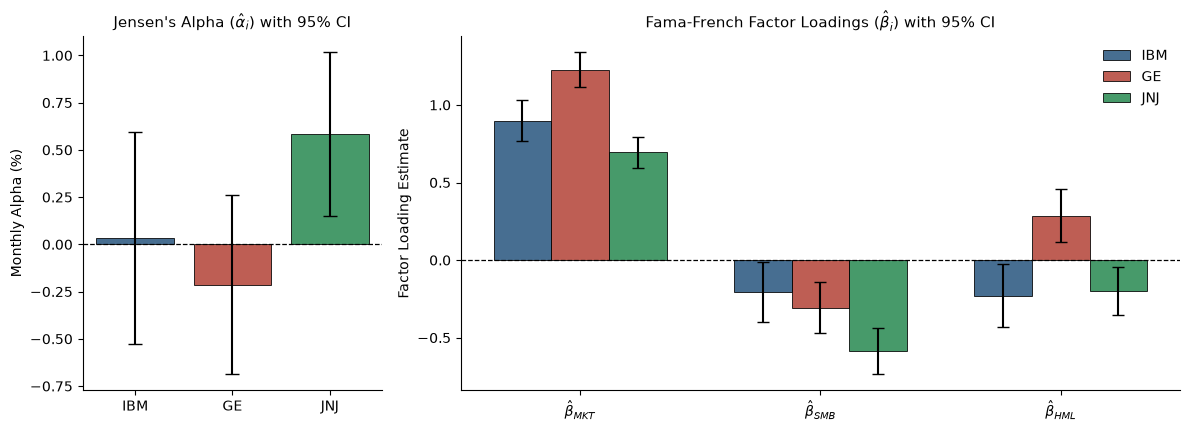

In [13]:
# Factor loadings and alpha comparison (saved to output/regression_betas_comparison.pdf)
fig, axes = plt.subplots(
    1, 2, figsize=(12.0, 4.4), gridspec_kw={"width_ratios": [1, 2.4]}
)

ax_a = axes[0]
alpha_sub = ols_df[ols_df["Parameter"] == "alpha"].set_index("Firm").loc[TICKERS]
x_pos = np.arange(len(TICKERS))
vals_a = alpha_sub["Estimate"].to_numpy() * 100.0
err_a = (alpha_sub["CI_95_High"].to_numpy() - alpha_sub["Estimate"].to_numpy()) * 100.0
ax_a.bar(
    x_pos,
    vals_a,
    yerr=err_a,
    capsize=5,
    color=colors,
    alpha=0.82,
    edgecolor="black",
    linewidth=0.7,
)
ax_a.axhline(0.0, color="black", linewidth=0.9, linestyle="--")
ax_a.set_xticks(x_pos)
ax_a.set_xticklabels(TICKERS)
ax_a.set_ylabel("Monthly Alpha (%)")
ax_a.set_title(r"Jensen's Alpha ($\hat{\alpha}_i$) with 95% CI")

ax_b = axes[1]
beta_params = ["beta_MKT", "beta_SMB", "beta_HML"]
beta_labels = [r"$\hat{\beta}_{MKT}$", r"$\hat{\beta}_{SMB}$", r"$\hat{\beta}_{HML}$"]
width = 0.24
x_base = np.arange(len(beta_params))
for i, (ticker, color) in enumerate(zip(TICKERS, colors)):
    sub = (
        ols_df[(ols_df["Firm"] == ticker) & (ols_df["Parameter"].isin(beta_params))]
        .set_index("Parameter")
        .loc[beta_params]
    )
    vals = sub["Estimate"].to_numpy()
    errs = sub["CI_95_High"].to_numpy() - vals
    ax_b.bar(
        x_base + (i - 1) * width,
        vals,
        width=width,
        yerr=errs,
        capsize=4,
        color=color,
        alpha=0.82,
        edgecolor="black",
        linewidth=0.7,
        label=ticker,
    )

ax_b.axhline(0.0, color="black", linewidth=0.9, linestyle="--")
ax_b.set_xticks(x_base)
ax_b.set_xticklabels(beta_labels)
ax_b.set_ylabel("Factor Loading Estimate")
ax_b.set_title(r"Fama-French Factor Loadings ($\hat{\beta}_i$) with 95% CI")
ax_b.legend(frameon=False, loc="upper right")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "regression_betas_comparison.pdf", bbox_inches="tight")
plt.show()